## Installations

In [1]:
%%capture

!pip install -q gdown albumentations

### Import Libraries

In [2]:
import os
import zipfile

from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import albumentations as A
from sklearn.model_selection import train_test_split
from tqdm import tqdm

## Configurations

In [3]:
CFG = {
    "seed" : 42,
    "img_size" : 512,
    "mask_threshold" : 127
}

## Download Dataset

In [4]:
file_id = "114xnPVZtthHi4Bejzho33vGJSqb4-F8g"
output_zip = "/content/dataset.zip"
extract_path = Path("/content/flopwd_data")

In [5]:
!gdown --id {file_id} -O {output_zip}

if os.path.exists(output_zip):
    os.makedirs(extract_path, exist_ok=True)
    with zipfile.ZipFile(output_zip, "r") as zip_ref:
        zip_ref.extractall(extract_path)
    print(f"Success! Dataset extracted to {extract_path}")

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=114xnPVZtthHi4Bejzho33vGJSqb4-F8g
From (redirected): https://drive.google.com/uc?id=114xnPVZtthHi4Bejzho33vGJSqb4-F8g&confirm=t&uuid=5ce87c54-f29b-4637-9904-2557e85e354b
To: /content/dataset.zip
100% 358M/358M [00:11<00:00, 30.2MB/s]
Success! Dataset extracted to /content/flopwd_data


## Import Dataset

In [6]:
dataset_path = extract_path / "Dal Lake Floating Plastic Waste Detection Dataset (FloPWD 2025)"
raw_dir = dataset_path / "Raw_Images"
mask_dir = dataset_path / "Segmentation_Masks"
labels_csv = dataset_path / "Image_labels_Binary Classification Task.csv"
reg_csv = dataset_path / "Mask_foreground_percentages_Regression Task.csv"

In [7]:
"images:", len(list(raw_dir.glob("*.jpg")))

('images:', 2002)

In [8]:
"masks :", len(list(mask_dir.glob("*.png")))

('masks :', 2002)

### Build Dataframe

In [9]:
labels_df = pd.read_csv(labels_csv)
reg_df = pd.read_csv(reg_csv)

labels_df.columns.tolist(), reg_df.columns.tolist()

(['image name', 'Presence of plastic waste?'],
 ['image name', 'plastic waste accumulation (in percentage)'])

- missing values & duplicate names

In [10]:
labels_df.isnull().sum().sum(), reg_df.isnull().sum().sum()

(np.int64(0), np.int64(0))

In [11]:
labels_df.iloc[:, 0].duplicated().sum(), reg_df.iloc[:, 0].duplicated().sum()

(np.int64(0), np.int64(0))

- rename columns

In [12]:
labels_df = labels_df.rename(columns={
    "image name" : "image_name",
    "Presence of plastic waste?" : "presence"
})

reg_df = reg_df.rename(columns={
    "image name" : "image_name",
    "plastic waste accumulation (in percentage)" : "fg_pct"
})

- merge

In [13]:
df = labels_df.merge(reg_df, on="image_name", how="inner")

df['image_path'] = df['image_name'].apply(lambda x: str(raw_dir / x))
df['mask_path'] = df['image_name'].str.replace('.jpg', "_mask.png", regex=False).apply(lambda x: str(mask_dir / x))
df['has_plastic'] = (df['presence'].astype(str).str.lower() == 'yes').astype(int)
df['fg_pct'] = df['fg_pct'].astype(float)

len(df)

2002

In [14]:
df.head()

,image_name,presence,fg_pct,image_path,mask_path,has_plastic
0,img1.jpg,yes,0.08,/content/flopwd_data/Dal Lake Floating Plastic...,/content/flopwd_data/Dal Lake Floating Plastic...,1
1,img2.jpg,yes,0.03,/content/flopwd_data/Dal Lake Floating Plastic...,/content/flopwd_data/Dal Lake Floating Plastic...,1
2,img3.jpg,yes,0.38,/content/flopwd_data/Dal Lake Floating Plastic...,/content/flopwd_data/Dal Lake Floating Plastic...,1
3,img4.jpg,yes,0.20,/content/flopwd_data/Dal Lake Floating Plastic...,/content/flopwd_data/Dal Lake Floating Plastic...,1
4,img5.jpg,yes,0.18,/content/flopwd_data/Dal Lake Floating Plastic...,/content/flopwd_data/Dal Lake Floating Plastic...,1


In [15]:
"every image has a mask:", df['mask_path'].apply(os.path.exists).all()

('every image has a mask:', np.True_)

## Label Distribution

In [16]:
counts = df['presence'].str.lower().value_counts()

counts, (counts / len(df) * 100).round(2)

(presence
 yes    1482
 no      520
 Name: count, dtype: int64,
 presence
 yes    74.03
 no     25.97
 Name: count, dtype: float64)

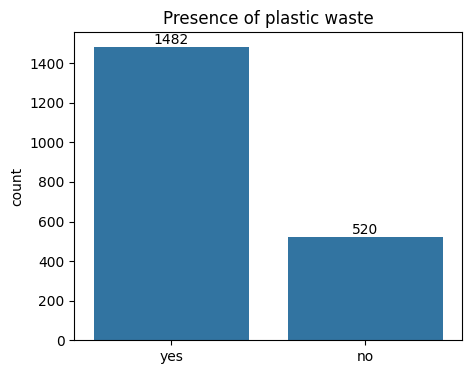

In [17]:
fig, ax = plt.subplots(figsize=(5, 4))

sns.countplot(x=df['presence'].str.lower(), order=["yes", "no"], ax=ax)
ax.set_title("Presence of plastic waste")
ax.set_xlabel("")

for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")

## Image & Mask Statistics

- read every image and mask once (original resolution)

In [18]:
rows = []
sizes = set()

fg_sum = bg_sum = 0.0
fg_n = bg_n = 0
mid_n = total_n = 0

for _, r in tqdm(df.iterrows(), total=len(df)):
    img = cv2.imread(r['image_path'])
    m = cv2.imread(r['mask_path'], cv2.IMREAD_GRAYSCALE)
    sizes.add((img.shape[:2], m.shape))

    mid_n += int(((m > 0) & (m < 255)).sum())
    total_n += m.size

    mask = m > CFG['mask_threshold']
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float64)
    sat = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)[..., 1]

    fg_sum += gray[mask].sum(); fg_n += int(mask.sum())
    bg_sum += gray[~mask].sum(); bg_n += int((~mask).sum())

    rows.append({
        "image_name" : r['image_name'],
        "fg_pct_mask" : mask.mean() * 100,
        "brightness" : gray.mean(),
        "saturation" : sat.mean(),
        "brightness_plastic" : gray[mask].mean() if mask.any() else np.nan,
        "brightness_background" : gray[~mask].mean()
    })

stats = df.merge(pd.DataFrame(rows), on="image_name")

100%|██████████| 2002/2002 [00:58<00:00, 34.23it/s]


In [19]:
sizes

{((720, 1280), (720, 1280))}

- mask values (not all pixels are 0 or 255)

In [20]:
m = cv2.imread(df['mask_path'].iloc[0], cv2.IMREAD_GRAYSCALE)

np.unique(m)[:10], len(np.unique(m))

(array([ 0,  1,  2,  3,  4,  6,  7,  8, 10, 12], dtype=uint8), 105)

In [21]:
"pixels between 0 and 255 (%):", round(mid_n / total_n * 100, 2)

('pixels between 0 and 255 (%):', 0.15)

-> mask is binarised with threshold 127 (plastic = 1, background = 0)

## Class Imbalance

In [22]:
plastic_pct = fg_n / (fg_n + bg_n) * 100

"plastic pixels (%):", round(plastic_pct, 2), "background pixels (%):", round(100 - plastic_pct, 2)

('plastic pixels (%):', 5.46, 'background pixels (%):', 94.54)

In [23]:
nonempty = stats[stats['fg_pct_mask'] > 0]

pd.Series({
    "mean plastic area per image (%)" : stats['fg_pct_mask'].mean(),
    "images with plastic in mask" : len(nonempty),
    "median plastic area, images with plastic (%)" : nonempty['fg_pct_mask'].median(),
    "empty masks" : (stats['fg_pct_mask'] == 0).sum()
}).round(2)

,0
mean plastic area per image (%),5.46
images with plastic in mask,1478.00
"median plastic area, images with plastic (%)",2.44
empty masks,524.00


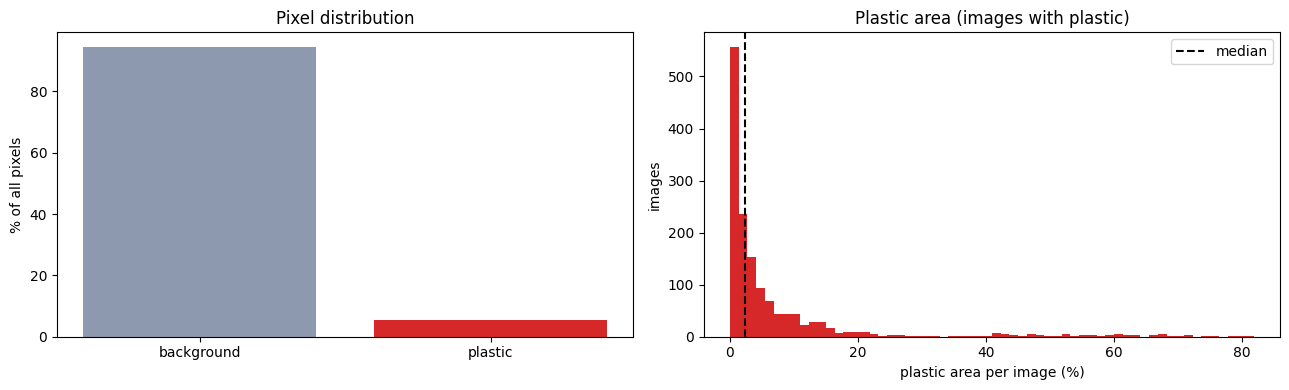

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].bar(["background", "plastic"], [100 - plastic_pct, plastic_pct], color=["#8d99ae", "#d62828"])
ax[0].set_ylabel("% of all pixels")
ax[0].set_title("Pixel distribution")

ax[1].hist(nonempty['fg_pct_mask'], bins=60, color="#d62828")
ax[1].axvline(nonempty['fg_pct_mask'].median(), color="black", ls="--", label="median")
ax[1].set_xlabel("plastic area per image (%)")
ax[1].set_ylabel("images")
ax[1].set_title("Plastic area (images with plastic)")
ax[1].legend()

plt.tight_layout()

- fg_pct (regression csv) vs mask

In [25]:
(stats['fg_pct'] - stats['fg_pct_mask']).abs().describe()

,0
count,2002.000000
mean,0.073520
std,0.173700
min,0.000000
25%,0.000000
50%,0.002567
75%,0.047850
max,1.380030


## Brightness

- plastic vs non-plastic area, per image (images with plastic only)

In [26]:
b = nonempty[['brightness_plastic', 'brightness_background']]

b.describe().round(2)

,brightness_plastic,brightness_background
count,1478.00,1478.00
mean,133.97,113.70
std,36.54,21.09
min,30.29,71.71
25%,105.31,96.64
50%,128.62,108.13
75%,163.94,128.15
max,229.67,181.02


In [27]:
"mean difference (plastic - non-plastic):", round(b['brightness_plastic'].mean() - b['brightness_background'].mean(), 2)

('mean difference (plastic - non-plastic):', np.float64(20.27))

Text(0.5, 1.0, 'Brightness: plastic vs non-plastic')

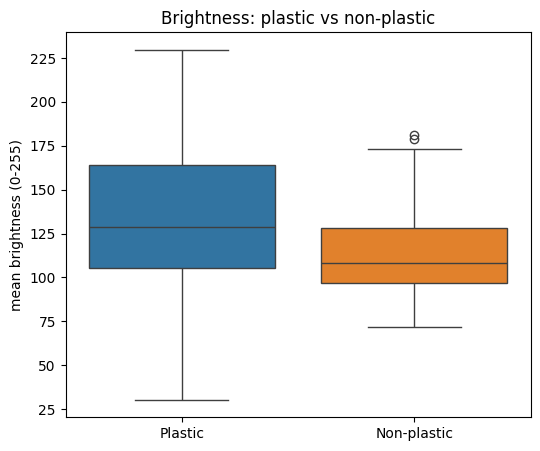

In [28]:
fig, ax = plt.subplots(figsize=(6, 5))

sns.boxplot(data=b.rename(columns={"brightness_plastic" : "Plastic", "brightness_background" : "Non-plastic"}), ax=ax)
ax.set_ylabel("mean brightness (0-255)")
ax.set_title("Brightness: plastic vs non-plastic")

- all pixels pooled

In [29]:
"pooled difference (plastic - non-plastic):", round(fg_sum / fg_n - bg_sum / bg_n, 2)

('pooled difference (plastic - non-plastic):', np.float64(-3.64))

- darkest & brightest images

In [30]:
order = stats.sort_values("brightness")
extreme = pd.concat([order.head(2), order.tail(2)])

extreme[['image_name', 'brightness', 'saturation']].round(1)

,image_name,brightness,saturation
797,img798.jpg,24.5,71.1
911,img912.jpg,71.8,71.6
241,img242.jpg,182.3,27.2
31,img32.jpg,189.2,16.8


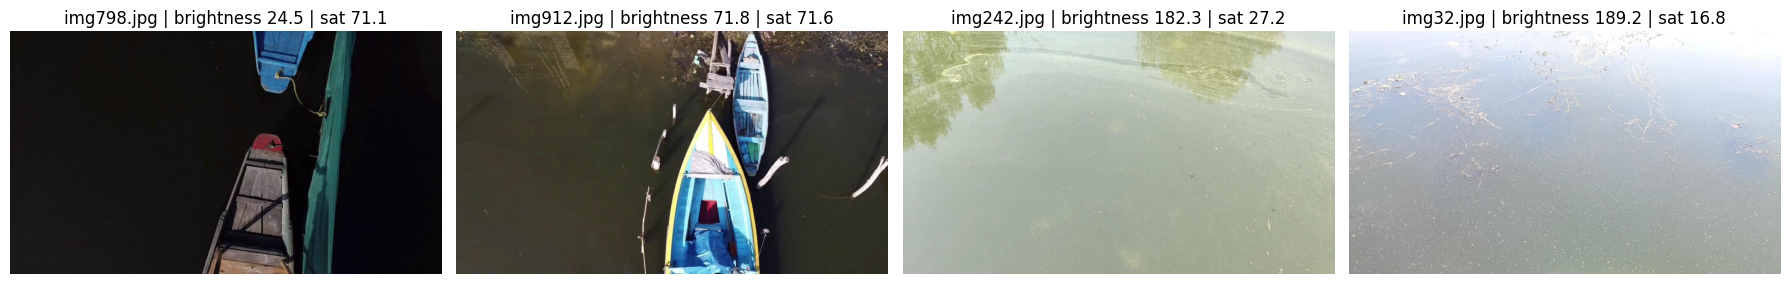

In [31]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.5))

for a, (_, r) in zip(ax, extreme.iterrows()):
    a.imshow(cv2.cvtColor(cv2.imread(r['image_path']), cv2.COLOR_BGR2RGB))
    a.set_title(f"{r['image_name']} | brightness {r['brightness']:.1f} | sat {r['saturation']:.1f}")
    a.axis("off")

plt.tight_layout()

## Mask Overlay
---

- non-target objects & polygon annotation

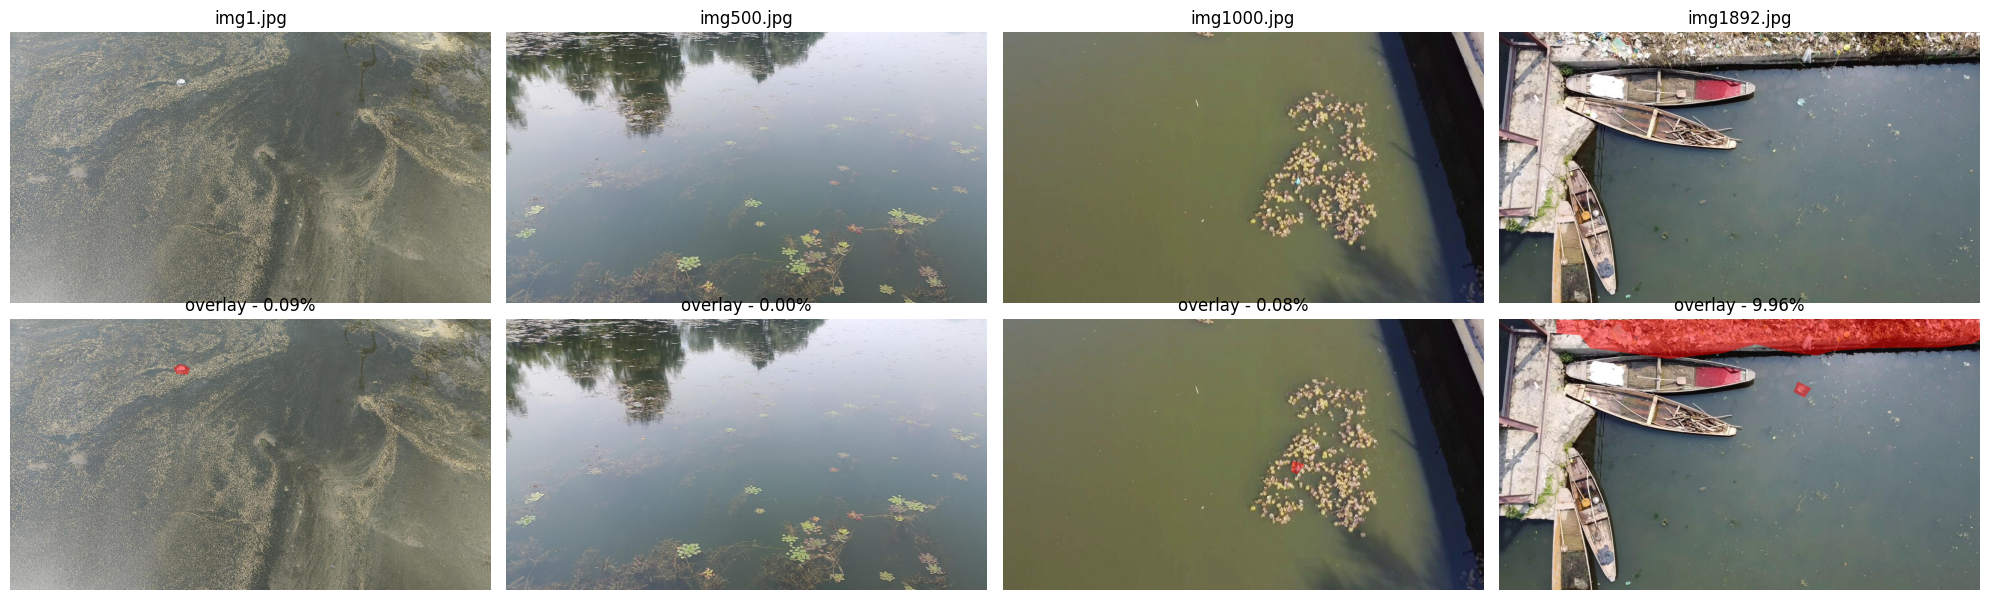

In [32]:
SAMPLES = ["img1.jpg", "img500.jpg", "img1000.jpg", "img1892.jpg"]

fig, ax = plt.subplots(2, len(SAMPLES), figsize=(5 * len(SAMPLES), 6))

for i, n in enumerate(SAMPLES):
    r = df[df.image_name == n].iloc[0]
    img = cv2.cvtColor(cv2.imread(r['image_path']), cv2.COLOR_BGR2RGB)
    mask = cv2.imread(r['mask_path'], cv2.IMREAD_GRAYSCALE) > CFG['mask_threshold']

    over = img.copy()
    over[mask] = (0.5 * over[mask] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)

    ax[0, i].imshow(img)
    ax[0, i].set_title(n)
    ax[1, i].imshow(over)
    ax[1, i].set_title(f"overlay - {mask.mean() * 100:.2f}%")

    for a in ax[:, i]:
        a.axis("off")

plt.tight_layout()

## Split
---

In [33]:
train_val_df, test_df = train_test_split(df, test_size=0.15, random_state=CFG['seed'], stratify=df['has_plastic'])
train_df, val_df = train_test_split(train_val_df, test_size=15/85, random_state=CFG['seed'], stratify=train_val_df['has_plastic'])

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

len(train_df), len(val_df), len(test_df)

(1400, 301, 301)

In [34]:
s = stats.set_index("image_name")

summary = []
for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    p = s.loc[part['image_name']]
    summary.append({
        "split" : name,
        "images" : len(part),
        "share (%)" : len(part) / len(df) * 100,
        "yes" : part['has_plastic'].sum(),
        "yes (%)" : part['has_plastic'].mean() * 100,
        "no" : (part['has_plastic'] == 0).sum(),
        "empty mask" : (p['fg_pct_mask'] == 0).sum(),
        "mean plastic area (%)" : p['fg_pct_mask'].mean()
    })

pd.DataFrame(summary).round(2)

,split,images,share (%),yes,yes (%),no,empty mask,mean plastic area (%)
0,train,1400,69.93,1036,74.00,364,367,5.33
1,val,301,15.03,223,74.09,78,78,6.12
2,test,301,15.03,223,74.09,78,79,5.37


## Class Weight

- background / plastic pixel ratio on 200 random training images (used as pos_weight in the loss)

In [35]:
sub = train_df.sample(
    min(200, len(train_df)),
    random_state=CFG['seed']
)

pos = 0
neg = 0

In [36]:
for _, r in sub.iterrows():
    mask = cv2.imread(r["mask_path"], cv2.IMREAD_GRAYSCALE) > 127
    pos += int(mask.sum())
    neg += int(mask.size - mask.sum())

In [37]:
pos_weight = neg / max(pos, 1)

pos_weight

18.368890673898054

## Augmentation Preview

In [38]:
S = CFG['img_size']

aug = [
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.2, rotate_limit=30, p=0.5),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1, p=0.4)
]

/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


img702.jpg in train: True | ['Resize', 'HorizontalFlip', 'VerticalFlip', 'RandomRotate90', 'ShiftScaleRotate', 'ColorJitter']
img335.jpg in train: True | ['Resize', 'HorizontalFlip', 'VerticalFlip', 'RandomRotate90', 'ShiftScaleRotate']


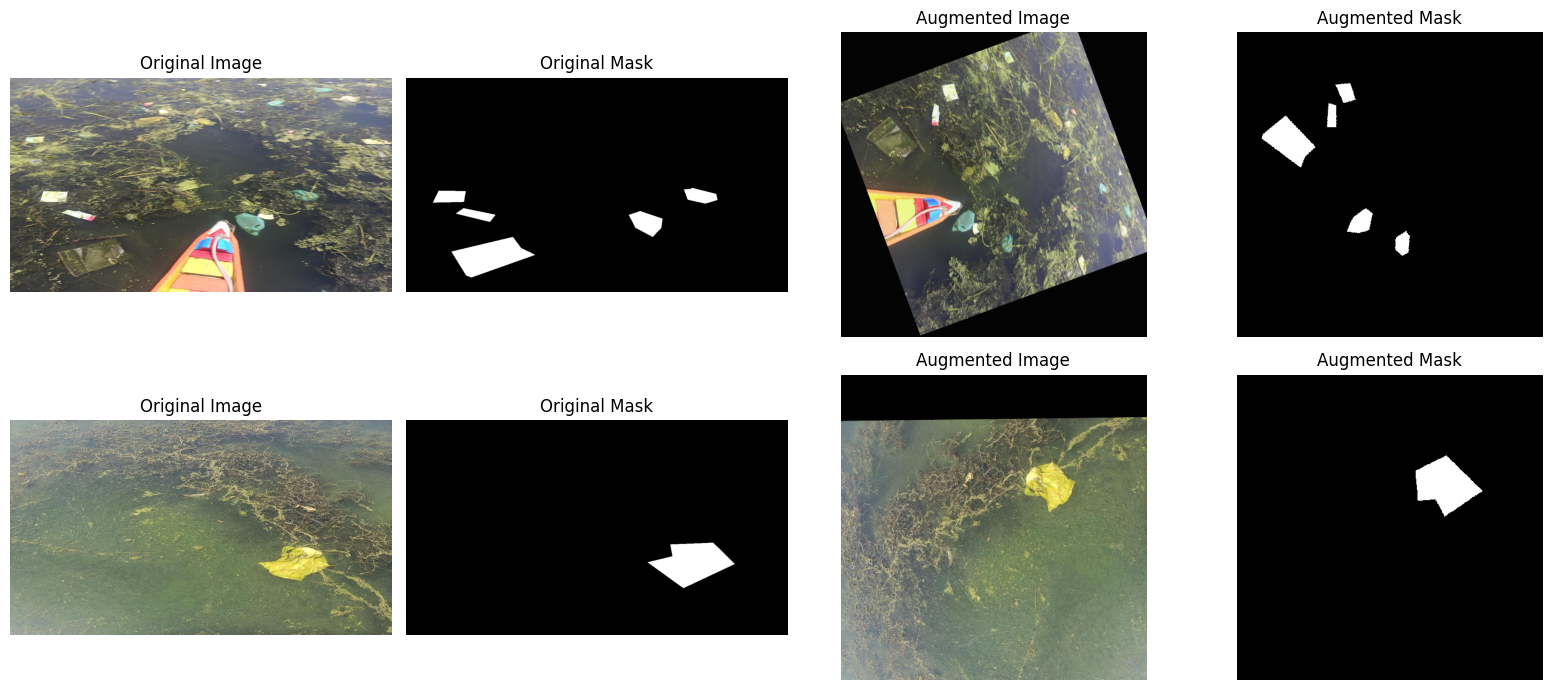

In [39]:
SAMPLES = [("img702.jpg", 3), ("img335.jpg", 11)]

fig, ax = plt.subplots(2, 4, figsize=(16, 7))

for i, (n, seed) in enumerate(SAMPLES):
    r = df[df.image_name == n].iloc[0]
    img = cv2.cvtColor(cv2.imread(r['image_path']), cv2.COLOR_BGR2RGB)
    mask = (cv2.imread(r['mask_path'], cv2.IMREAD_GRAYSCALE) > CFG['mask_threshold']).astype(np.uint8)

    out = A.Compose([A.Resize(S, S)] + aug, seed=seed, save_applied_params=True)(image=img, mask=mask)
    print(n, "in train:", n in set(train_df['image_name']), "|", [t for t, _ in out["applied_transforms"]])

    for j, (x, title) in enumerate([(img, "Original Image"), (mask, "Original Mask"), (out["image"], "Augmented Image"), (out["mask"], "Augmented Mask")]):
        ax[i, j].imshow(x, cmap="gray" if x.ndim == 2 else None)
        ax[i, j].set_title(title)
        ax[i, j].axis("off")

plt.tight_layout()

## Coverage Category

- None / Low / Moderate / High, split by the tertiles of fg_pct (images with plastic)

In [40]:
cov = df.loc[df['fg_pct'] > 0, 'fg_pct']

len(cov), np.percentile(cov, [100/3, 200/3]).round(2)

(1474, array([1.1 , 4.47]))

Text(0.5, 1.0, 'Coverage category thresholds: 1.1% and 4.5%')

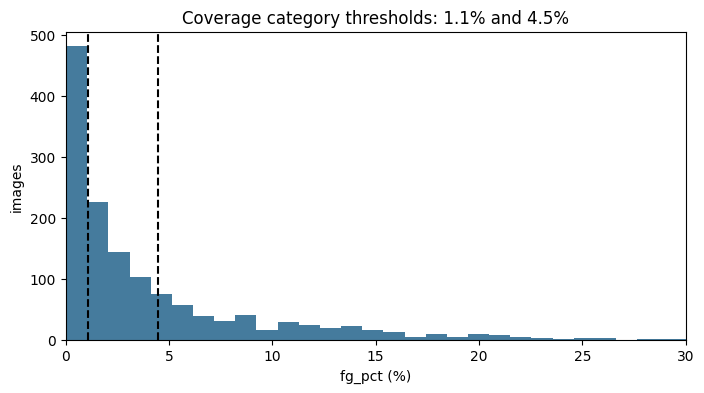

In [41]:
low, high = np.percentile(cov, [100/3, 200/3])

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(cov, bins=80, color="#457b9d")
for v in (low, high):
    ax.axvline(v, color="black", ls="--")
ax.set_xlim(0, 30)
ax.set_xlabel("fg_pct (%)")
ax.set_ylabel("images")
ax.set_title(f"Coverage category thresholds: {low:.1f}% and {high:.1f}%")